# 08 · La EDR como nivel de la noche

En la feature C la EDR entra solo como **nivel de la noche**, que se compara entre personas. Este notebook revisa la EDR con ese papel en mente, solo con los registros de desarrollo:

1. **Qué banda se mide en realidad.** Si alguna etapa del pipeline pierde potencia en las frecuencias de la apnea, y cuáles.
2. **Las decisiones de la EDR**, con el criterio registrado antes de calcularlas (`docs/criterio_edr.md`).

Test no se usa.

In [1]:
import json
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from src.config import ECG_FILTER, MINUTE_MAX_CORRECTED, SPLIT_CSV
from src.data import load_apnea_labels, load_ecg
from src.features.build import record_series
from src.features.coupling import resample_uniform, welch_spectra
from src.features.detector import BAND, BANDA_EFECTIVA, FS_U, WINDOW_S
from src.features.edr import beat_edr
from src.preprocessing.wiener import wiener_from_beats
from src.qrs.beats import record_beats
from src.viz.plots import ANCHO, APNEA, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
RAPIDO = bool(__import__("os").environ.get("NB08_RAPIDO"))   # solo para probar el código: 16 registros y pocos sorteos
if RAPIDO:
    DEV = DEV[:16]

## 1. Qué banda se mide en realidad

La banda se escribió como 0,01–0,05 Hz, porque la apnea tiene ciclos de entre 20 y 100 s (Guilleminault et al., 1984). Hay que verificar si cada etapa del pipeline deja pasar esas frecuencias. Una observación de la bibliografía motiva la pregunta: los algoritmos que estiman la frecuencia respiratoria con el ECG empiezan por eliminar todo lo que está por debajo de 0,03–0,05 Hz (Charlton et al., 2018). Este pipeline no aplica ese paso, pero conviene medir qué pasa en cada etapa.

Se miden tres etapas con simulaciones, sin etiquetas:
- el filtro del ECG y el Wiener, sobre un QRS cuya amplitud oscila lentamente;
- la interpolación a 2 Hz desde los tiempos reales de los latidos;
- el estimador de Welch con segmentos de 120 s.

### Filtro del ECG y Wiener

Se arma un ECG sintético con el latido típico de `a03`, ubicado en los tiempos reales de sus latidos (3 h), con una amplitud que oscila un 10 % a la frecuencia f, más un ruido blanco chico. Se mide la EDR (área relativa del QRS) y se estima la amplitud de la oscilación a la frecuencia f. Una ganancia de 1 quiere decir que la oscilación se conserva.

In [2]:
F_PRUEBA = 1 / np.array([100, 80, 60, 40, 30, 20, 4.0])   # períodos en s
ecg, fs = load_ecg("a03")
t_r = record_beats("a03")["t_r"]
t_r = t_r[(t_r > 10) & (t_r < 3 * 3600)]
k_r = np.rint(t_r * fs).astype(int)
pre, post = int(0.25 * fs), int(0.40 * fs)
plantilla = np.median(np.stack([ecg[i - pre:i + post + 1] for i in k_r[1:-1]]), axis=0)
plantilla = plantilla - np.linspace(plantilla[0], plantilla[-1], len(plantilla))


def amplitud_en(t, v, f):
    """Amplitud relativa de la componente de frecuencia f (mínimos cuadrados con seno, coseno y constante)."""
    X = np.c_[np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t), np.ones_like(t)]
    b = np.linalg.lstsq(X, v, rcond=None)[0]
    return np.hypot(b[0], b[1]) / abs(b[2])


M_MOD = 0.10
rng = np.random.default_rng(0)
filas = []
for f in F_PRUEBA:
    fase = rng.uniform(0, 2 * np.pi)
    sint = np.zeros(len(ecg))
    for ti, i in zip(t_r, k_r):
        if i - pre >= 0 and i + post + 1 <= len(ecg):
            sint[i - pre:i + post + 1] += plantilla * (1 + M_MOD * np.sin(2 * np.pi * f * ti + fase))
    sint += rng.normal(0, 0.02 * np.ptp(plantilla), len(sint))
    fila = {"f (Hz)": f, "período (s)": round(1 / f)}
    for nom, pref in (("filtro 0,5–45 Hz", None), ("filtro + Wiener", lambda s_: wiener_from_beats(s_, t_r, fs))):
        t, v = beat_edr(sint, t_r, fs, "area", ECG_FILTER, prefilter=pref, relative=True)
        fila[nom] = amplitud_en(t, v, f) / M_MOD
    filas.append(fila)
pd.DataFrame(filas).set_index("f (Hz)").rename(index=lambda x: round(x, 4)).round(3)

,período (s),"filtro 0,5–45 Hz",filtro + Wiener
f (Hz),,,
0.0100,100,0.997,0.997
0.0125,80,1.003,1.003
0.0167,60,1.008,1.007
0.0250,40,1.008,1.008
0.0333,30,0.991,0.991
0.0500,20,0.985,0.985
0.2500,4,0.987,0.987


Las dos etapas conservan la oscilación (ganancia entre 0,98 y 1,01). Actúan sobre la **forma** de cada latido, y la oscilación lenta de la apnea está en cómo cambia el latido de uno al siguiente, no en esa forma.

### Interpolación a 2 Hz

Se muestrea una sinusoide de frecuencia f en los tiempos reales de los latidos y se interpola a la grilla de 2 Hz, de forma lineal y con spline cúbico.

In [3]:
filas = []
for f in F_PRUEBA:
    s = np.sin(2 * np.pi * f * t_r)
    fila = {"f (Hz)": f, "período (s)": round(1 / f)}
    for kind, nom in (("linear", "lineal"), ("cubic", "spline cúbico")):
        tu, su = resample_uniform(t_r, s + 10, FS_U, kind)
        fila[f"{nom}: potencia que conserva"] = (amplitud_en(tu, su, f) * 10) ** 2
    filas.append(fila)
pd.DataFrame(filas).set_index("f (Hz)").rename(index=lambda x: round(x, 4)).round(3)

,período (s),lineal: potencia que conserva,spline cúbico: potencia que conserva
f (Hz),,,
0.0100,100,0.999,1.000
0.0125,80,0.999,1.000
0.0167,60,0.998,1.000
0.0250,40,0.996,1.000
0.0333,30,0.993,1.000
0.0500,20,0.985,1.000
0.2500,4,0.682,0.968


En la banda de la apnea las dos conservan prácticamente toda la potencia: la lineal pierde 1,5 % en 0,05 Hz. En la banda respiratoria (0,25 Hz) la lineal pierde un tercio y el spline cúbico, 3 %.

### El estimador de Welch

Con segmentos de 120 s, el espectro se calcula en las frecuencias k/120 Hz, y la feature suma k = 2…6. Se calcula qué fracción de la potencia de una sinusoide de frecuencia f termina en esas cinco frecuencias, promediando 16 fases, con cada forma de quitar la tendencia.

In [4]:
n_w = int(WINDOW_S * FS_U)
t_w = np.arange(n_w) / FS_U
f_cap = np.round(np.arange(0.004, 0.0701, 0.001), 4)
cap = {}
for dt, nom in (("linear", "quitando la recta"), ("constant", "quitando la media")):
    vals = []
    for f in f_cap:
        c = []
        for fase in np.linspace(0, 2 * np.pi, 16, endpoint=False):
            x = np.sin(2 * np.pi * f * t_w + fase)
            fr, sxx, _, _ = welch_spectra(x, x, FS_U, n_w // 2, dt)
            b = (fr >= BAND[0] - 1e-9) & (fr <= BAND[1] + 1e-9)
            c.append(sxx[b].sum() * (fr[1] - fr[0]) / 0.5)
        vals.append(np.mean(c))
    cap[nom] = np.array(vals)
cap = pd.DataFrame(cap, index=f_cap)
med = cap["quitando la media"].to_numpy()
i_lo = int(np.argmax(med >= 0.5)); j_hi = len(med) - 1 - int(np.argmax(med[::-1] >= 0.5))
borde_bajo = float(np.interp(0.5, med[i_lo - 1:i_lo + 1], f_cap[i_lo - 1:i_lo + 1]))
borde_alto = float(np.interp(0.5, med[j_hi:j_hi + 2][::-1], f_cap[j_hi:j_hi + 2][::-1]))
print(f"frecuencias que suma la feature (k = 2…6): {BANDA_EFECTIVA[0]:.4f} a {BANDA_EFECTIVA[1]:.4f} Hz")
print(f"mitad de potencia: {borde_bajo:.4f} Hz ({1 / borde_bajo:.0f} s) y {borde_alto:.4f} Hz ({1 / borde_alto:.0f} s)")
cap.assign(**{"período (s)": np.round(1 / cap.index)}).iloc[2::2].round(3)

frecuencias que suma la feature (k = 2…6): 0.0167 a 0.0500 Hz
mitad de potencia: 0.0125 Hz (80 s) y 0.0542 Hz (18 s)


,quitando la recta,quitando la media,período (s)
0.006,0.038,0.061,167.0
0.008,0.117,0.147,125.0
0.010,0.261,0.283,100.0
0.012,0.456,0.455,83.0
0.014,0.659,0.634,71.0
0.016,0.823,0.791,62.0
0.018,0.924,0.902,56.0
0.020,0.969,0.966,50.0
0.022,0.985,0.993,45.0
0.024,0.991,1.000,42.0


### ¿Importa lo que se pierde? El aumento con la apnea, con el doble de resolución

La banda de `01` se midió con el mismo estimador, que casi no ve por debajo de 0,017 Hz. Para no razonar en círculo, se repite con el doble de resolución: ventanas de 480 s con segmentos de 240 s (frecuencias cada 1/240 Hz). Se toman las ventanas centradas en 8 minutos seguidos de la misma clase, apnea o normal, y en cada registro con al menos 5 ventanas de cada clase se calcula el aumento de potencia con la apnea, en dB.

In [5]:
W_ALTA, SEG_ALTA = 480, 240


def espectros_por_clase(rec):
    s = record_series(rec)
    lab = load_apnea_labels(rec)
    t = s["t"]
    out = {c: {"rr": [], "edr": []} for c in ("apnea", "normal")}
    f = None
    for m in range(4, len(lab) - 4):
        bloque = lab[m - 4:m + 4]
        if (bloque < 0).any() or len(set(bloque)) > 1:
            continue
        i = int(round((60 * m - W_ALTA / 2 - t[0]) * FS_U)); n = int(W_ALTA * FS_U)
        if i < 0 or i + n > len(t):
            continue
        clase = "apnea" if bloque[0] == 1 else "normal"
        for k in ("rr", "edr"):
            f, p = welch(s[k][i:i + n], fs=FS_U, nperseg=int(SEG_ALTA * FS_U), detrend="constant", window="hann")
            out[clase][k].append(p)
    res = {k: (np.mean(out["apnea"][k], axis=0), np.mean(out["normal"][k], axis=0))
           for k in ("rr", "edr") if len(out["apnea"][k]) >= 5 and len(out["normal"][k]) >= 5}
    return f, res


with ProcessPoolExecutor(4) as ex:
    ESP = list(ex.map(espectros_por_clase, DEV))
f_alta = next(f for f, r in ESP if f is not None)
sel = (f_alta > 0) & (f_alta <= 0.08)
aumento = {}
for k in ("rr", "edr"):
    pa = np.array([r[k][0] for _, r in ESP if k in r]); pn = np.array([r[k][1] for _, r in ESP if k in r])
    aumento[k.upper()] = np.median(10 * np.log10(pa[:, sel] / pn[:, sel]), axis=0)
print("registros con al menos 5 ventanas de cada clase:", sum(1 for _, r in ESP if "rr" in r))
tab_aum = pd.DataFrame({"período (s)": np.round(1 / f_alta[sel]), **{f"aumento {k} (dB)": v for k, v in aumento.items()}},
                       index=np.round(f_alta[sel], 4)).rename_axis("f (Hz)")
tab_aum.round(1)

registros con al menos 5 ventanas de cada clase: 32


,período (s),aumento RR (dB),aumento EDR (dB)
f (Hz),,,
0.0042,240.0,0.6,0.4
0.0083,120.0,2.2,1.6
0.0125,80.0,3.8,2.6
0.0167,60.0,6.6,4.6
0.0208,48.0,7.9,5.0
0.0250,40.0,8.3,5.1
0.0292,34.0,8.0,4.6
0.0333,30.0,7.6,3.6
0.0375,27.0,6.7,2.6


PosixPath('/home/user/TP-PSB-G8/informe/figuras/08_banda_efectiva.png')

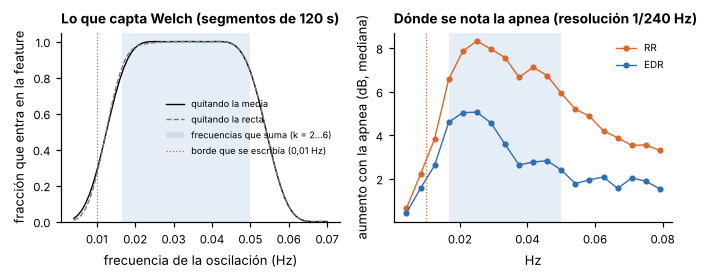

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
axs[0].plot(f_cap, cap["quitando la media"], color="black", label="quitando la media")
axs[0].plot(f_cap, cap["quitando la recta"], color=GRIS, ls="--", label="quitando la recta")
axs[0].axvspan(*BANDA_EFECTIVA, color=NORMAL, alpha=0.12, lw=0, label="frecuencias que suma (k = 2…6)")
axs[0].axvline(BAND[0], color=APNEA, ls=":", lw=0.8, label="borde que se escribía (0,01 Hz)")
axs[0].set(xlabel="frecuencia de la oscilación (Hz)", ylabel="fracción que entra en la feature", ylim=(0, 1.05),
           title="Lo que capta Welch (segmentos de 120 s)")
axs[0].legend(fontsize=6)
for k, c in (("RR", APNEA), ("EDR", NORMAL)):
    axs[1].plot(f_alta[sel], aumento[k], marker="o", ms=3, color=c, label=k)
axs[1].axvspan(*BANDA_EFECTIVA, color=NORMAL, alpha=0.12, lw=0)
axs[1].axvline(BAND[0], color=APNEA, ls=":", lw=0.8)
axs[1].set(xlabel="Hz", ylabel="aumento con la apnea (dB, mediana)", title="Dónde se nota la apnea (resolución 1/240 Hz)")
axs[1].legend(fontsize=6.5)
fig.tight_layout()
save(fig, "08_banda_efectiva")

**Qué se ve.**
- **Ninguna etapa pierde la oscilación de la apnea, salvo el borde bajo de Welch.** El filtro, el Wiener y la interpolación la conservan. Welch capta entre 83 % y 100 % de las oscilaciones de 20 a 60 s; las de 60 a 100 s entran solo en parte (entre ~25 % y ~80 %), y las de más de 100 s casi nada.
- **No es la tendencia que se quita:** quitar la recta o la media da casi lo mismo. Es la resolución: con segmentos de 120 s el espectro se calcula cada 0,0083 Hz, y la ventana de Hann reparte una oscilación de 100 s entre 0,0083 Hz, que no se suma, y 0,017 Hz, que sí.
- **Lo que se pierde es lo que menos distingue la apnea.** Con el doble de resolución, el aumento con la apnea es máximo entre 40 y 48 s de período (RR ~+8 dB, EDR ~+5 dB) y baja por debajo de 0,017 Hz (en 80 s: RR ~+4 dB, EDR ~+3 dB). Por encima de 100 s casi no hay aumento: son cambios de etapa del sueño, de postura o de toda la noche, no ciclos de apnea.
- **El borde de arriba también es suave.** Entran en parte oscilaciones de 17 a 20 s, donde la apnea todavía aumenta la potencia del RR.

**Conclusión: la banda que se mide es 0,017–0,05 Hz** (las frecuencias k = 2…6), con bordes suaves que caen a la mitad de la potencia en ~80 s y ~18 s de período. El borde de 0,01 Hz que se escribía era nominal. Los cálculos no cambian, porque siempre se sumaron esas mismas cinco frecuencias. Una ventana más larga vería mejor los ciclos de 60 a 100 s, pero en desarrollo no mejoró la detección (con 360 s empeoró de forma demostrable, `04` §15): se informa como limitación.

## 2. Las decisiones de la EDR, con el criterio registrado

El criterio está en `docs/criterio_edr.md`, escrito y subido antes de calcular nada de esta sección. En resumen:

| Paso | Qué se mide |
|---|---|
| Requisito de validez | La variante no puede empeorar de forma demostrable el parecido con la respiración registrada (A1, 8 registros, como en `03` §6) |
| Medida de decisión | **P2 en desarrollo**: ρ de Spearman entre el nivel nocturno de la EDR y el % de minutos con apnea, en las 47 noches. No ajusta nada, así que el bootstrap por personas es válido sin repetir ningún ajuste |
| Regla | Una etapa que agrega pasos se mantiene solo si mejora P2 de forma demostrable (Holm). Entre alternativas de igual complejidad se mantiene la actual, salvo que la otra sea demostrablemente mejor; si no hay diferencia y la bibliografía tiene un estándar, se usa el estándar |
| Familia de Holm | Estas 8 pruebas junto con las 9 de `07` |

La base es la EDR del detector simplificado de `07`: área relativa del QRS sobre el ECG filtrado, sin Wiener ni exclusiones, interpolación lineal y Welch quitando la media. Se cambia un elemento por vez.

In [7]:
from scipy.stats import spearmanr

from src.config import RESP_RECORDS
from src.data import load_respiration
from src.estadistica import holm, p_bootstrap
from src.evaluation.cv import cv_c, exactitud, metricas, sorteos_personas
from src.features.coupling import downsample
from src.features.detector import evaluable, minute_table
from src.features.edr import validate_edr

SUJETO = split.set_index("record").subject
PERSONAS = sorted(SUJETO[DEV].unique())
BASE = {"edr_method": "area", "wiener": False, "exclude_ectopic": False, "hampel": False,
        "aberrant": False, "relative": True, "interp": "linear"}
VARIANTES_E = {
    "base (área relativa)": {}, "deriva de línea de base": {"edr_method": "baseline"}, "área + deriva": {"edr_method": "combined"},
    "con Wiener": {"wiener": True}, "sin latidos ectópicos": {"exclude_ectopic": True},
    "sin atípicos (Hampel)": {"hampel": True}, "sin aberrantes (Varon et al., 2020)": {"aberrant": True},
    "en mV·ms (sin dividir)": {"relative": False}, "spline cúbico": {"interp": "cubic"},
}


def medir_variante(args):
    """Nivel nocturno de la EDR y, si hay respiración registrada, A1 (como en 03 §6)."""
    rec, nombre = args
    s = record_series(rec, **{**BASE, **VARIANTES_E[nombre]})
    t = minute_table(rec, series=s, detrend_type="constant")
    fila = {"record": rec, "variante": nombre, "nivel": float(t.EDR_noche.iloc[0])}
    if rec in RESP_RECORDS:
        resp, fr = load_respiration(rec)
        idx = np.rint(s["t"] * FS_U).astype(int)
        a1 = []
        for canal in ("Resp C", "Resp A", "Resp N"):
            r2 = downsample(resp[canal], fr, FS_U); ok = idx < len(r2)
            a1.append(np.nanmedian(validate_edr(s["edr"][ok], r2[idx[ok]], FS_U)))
        fila["A1"] = float(np.mean(a1))
    return fila


with ProcessPoolExecutor(4) as ex:
    MED = pd.DataFrame(list(ex.map(medir_variante, [(r, n) for n in VARIANTES_E for r in DEV])))
NIVEL = MED.pivot(index="record", columns="variante", values="nivel")[list(VARIANTES_E)]
A1 = MED.dropna(subset=["A1"]).pivot(index="record", columns="variante", values="A1")[list(VARIANTES_E)]
FRAC = pd.Series({r: float((load_apnea_labels(r)[load_apnea_labels(r) >= 0] == 1).mean()) for r in DEV})
pd.DataFrame({"P2 en desarrollo": {v: spearmanr(NIVEL[v], FRAC.reindex(NIVEL.index))[0] for v in VARIANTES_E},
              "A1 (media de los 8 registros)": A1.mean()}).round(3)

,P2 en desarrollo,A1 (media de los 8 registros)
base (área relativa),0.781,0.537
deriva de línea de base,0.418,0.456
área + deriva,0.754,0.492
con Wiener,0.831,0.552
sin latidos ectópicos,0.766,0.546
sin atípicos (Hampel),0.785,0.549
"sin aberrantes (Varon et al., 2020)",0.763,0.553
en mV·ms (sin dividir),0.710,0.537
spline cúbico,0.782,0.535


**Las 8 pruebas.** Cada diferencia se escribe de modo que **un valor positivo favorece a la etapa** (o a la alternativa que reemplazaría a la actual). El intervalo y el p salen de un bootstrap pareado por personas: en cada sorteo se toman todas las noches de las personas sorteadas y se recalcula P2 con las dos variantes sobre esas mismas noches.

In [8]:
PRUEBAS_E = {
    "E1 · deriva − área": ("deriva de línea de base", "base (área relativa)"),
    "E1 · área + deriva − área": ("área + deriva", "base (área relativa)"),
    "E2 · con Wiener − sin": ("con Wiener", "base (área relativa)"),
    "E3 · sin ectópicos − con": ("sin latidos ectópicos", "base (área relativa)"),
    "E4 · sin atípicos (Hampel) − ninguno": ("sin atípicos (Hampel)", "base (área relativa)"),
    "E4 · sin aberrantes (Varon) − ninguno": ("sin aberrantes (Varon et al., 2020)", "base (área relativa)"),
    "E5 · relativa − en mV·ms": ("base (área relativa)", "en mV·ms (sin dividir)"),
    "E6 · cúbica − lineal": ("spline cúbico", "base (área relativa)"),
}
SORTEOS = sorteos_personas(PERSONAS, n=200 if RAPIDO else 4000, semilla=2026)
recs = NIVEL.index.to_numpy(); frac = FRAC.reindex(recs).to_numpy()
filas_de = {u: np.flatnonzero(SUJETO.reindex(recs).to_numpy() == u) for u in PERSONAS}
idx_sorteos = [np.concatenate([filas_de[u] for u in so]) for so in SORTEOS]
recs_a1 = A1.index.to_numpy()
personas_a1 = sorted(SUJETO[recs_a1].unique())
filas_a1 = {u: np.flatnonzero(SUJETO.reindex(recs_a1).to_numpy() == u) for u in personas_a1}
idx_a1 = [np.concatenate([filas_a1[u] for u in so]) for so in sorteos_personas(personas_a1, n=200 if RAPIDO else 4000, semilla=2026)]


def delta_p2(a, b):
    xa, xb = NIVEL[a].to_numpy(), NIVEL[b].to_numpy()
    d = spearmanr(xa, frac)[0] - spearmanr(xb, frac)[0]
    boot = np.array([spearmanr(xa[i], frac[i])[0] - spearmanr(xb[i], frac[i])[0] for i in idx_sorteos])
    return d, boot


def delta_a1(a, b):
    d_ = (A1[a] - A1[b]).to_numpy()
    return float(d_.mean()), np.array([d_[i].mean() for i in idx_a1])


RES_E = {}
for nombre, (a, b) in PRUEBAS_E.items():
    d, boot = delta_p2(a, b)
    da, boot_a = delta_a1(a, b)
    RES_E[nombre] = {"ΔP2": d, "IC 95 % ΔP2": f"{np.percentile(boot, 2.5):+.3f} a {np.percentile(boot, 97.5):+.3f}",
                     "p (P2)": p_bootstrap(boot), "ΔA1": da, "p (A1)": p_bootstrap(boot_a)}

# p corregidos de las 9 pruebas de 07 (07 §7, bootstrap que repite el ajuste)
P_07 = {"07 · 1c refinamiento": 0.911, "07 · 2c Wiener": 0.998, "07 · 3c ectópicos": 0.777, "07 · 4c Hampel": 0.610,
        "07 · 5c interpolación": 0.929, "07 · 6c tendencia": 0.920, "07 · 7a minutos excluidos": 0.597,
        "07 · 7b ajuste sin esos minutos": 0.999, "07 · 8 confianza": 0.056}
ph = holm({**P_07, **{k: v["p (P2)"] for k, v in RES_E.items()}})
ph_a1 = holm({k: v["p (A1)"] for k, v in RES_E.items() if np.isfinite(v["p (A1)"])})
tab_e = pd.DataFrame(RES_E).T
tab_e["p de Holm (P2; familia de 17)"] = [ph.get(k, np.nan) for k in tab_e.index]
tab_e["p de Holm (A1; familia de la validez)"] = [ph_a1.get(k, np.nan) for k in tab_e.index]
tab_e["mejora P2 de forma demostrable"] = np.where((tab_e["ΔP2"].astype(float) > 0) & (tab_e["p de Holm (P2; familia de 17)"] < 0.05), "sí", "no")
tab_e["empeora A1 de forma demostrable"] = np.where((tab_e["ΔA1"].astype(float) < 0) & (tab_e["p de Holm (A1; familia de la validez)"] < 0.05), "sí", "no")
tab_e

,ΔP2,IC 95 % ΔP2,p (P2),ΔA1,p (A1),p de Holm (P2; familia de 17),p de Holm (A1; familia de la validez),mejora P2 de forma demostrable,empeora A1 de forma demostrable
E1 · deriva − área,-0.363021,-0.760 a -0.059,0.016,-0.08106,0.0905,0.272,0.5430,no,no
E1 · área + deriva − área,-0.027297,-0.262 a +0.198,0.763,-0.044805,0.211,1.000,0.8440,no,no
E2 · con Wiener − sin,0.049795,-0.039 a +0.183,0.3415,0.014325,0.025,1.000,0.1750,no,no
E3 · sin ectópicos − con,-0.015557,-0.054 a +0.007,0.2975,0.008821,0.7025,1.000,1.0000,no,no
E4 · sin atípicos (Hampel) − ninguno,0.00347,-0.067 a +0.095,0.978,0.011807,0.652,1.000,1.0000,no,no
E4 · sin aberrantes (Varon) − ninguno,-0.017813,-0.056 a +0.010,0.268,0.015333,0.1255,1.000,0.6275,no,no
E5 · relativa − en mV·ms,0.071598,-0.123 a +0.335,0.4685,0.0,NaN,1.000,NaN,no,no
E6 · cúbica − lineal,0.000347,-0.011 a +0.013,1.0,-0.002132,0.485,1.000,1.0000,no,no


PosixPath('/home/user/TP-PSB-G8/informe/figuras/08_decisiones_edr.png')

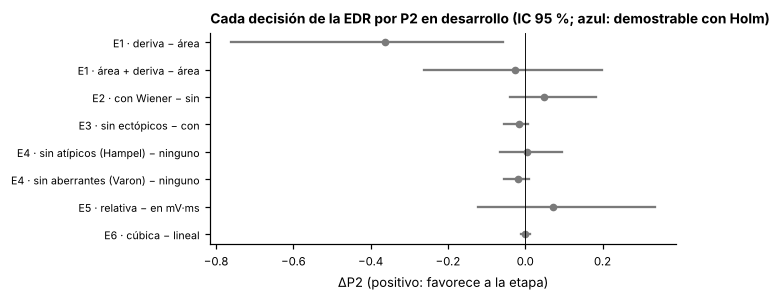

In [9]:
fig, ax = plt.subplots(figsize=(ANCHO, 2.8))
for i, nombre in enumerate(list(PRUEBAS_E)[::-1]):
    d, boot = delta_p2(*PRUEBAS_E[nombre])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    color = NORMAL if tab_e.loc[nombre, "mejora P2 de forma demostrable"] == "sí" else GRIS
    ax.plot([lo, hi], [i, i], color=color, lw=1.5); ax.plot(d, i, "o", color=color, ms=4)
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(range(len(PRUEBAS_E))); ax.set_yticklabels(list(PRUEBAS_E)[::-1], fontsize=7)
ax.set(xlabel="ΔP2 (positivo: favorece a la etapa)", title="Cada decisión de la EDR por P2 en desarrollo (IC 95 %; azul: demostrable con Holm)")
fig.tight_layout()
save(fig, "08_decisiones_edr")

**La decisión sale de aplicar la regla registrada.**

In [10]:
def demostrable(n):
    return tab_e.loc[n, "mejora P2 de forma demostrable"] == "sí" and tab_e.loc[n, "empeora A1 de forma demostrable"] == "no"


FINAL = dict(BASE)
decisiones = []
if demostrable("E1 · área + deriva − área"):
    FINAL["edr_method"] = "combined"; decisiones.append(("E1 · método", "área + deriva", "mejora P2 de forma demostrable"))
elif demostrable("E1 · deriva − área"):
    FINAL["edr_method"] = "baseline"; decisiones.append(("E1 · método", "deriva", "mejora P2 de forma demostrable"))
else:
    decisiones.append(("E1 · método", "área (se mantiene)", "ninguna alternativa mejora P2 de forma demostrable"))
for n, clave, si, no in (("E2 · con Wiener − sin", "wiener", "con Wiener", "sin Wiener"),
                         ("E3 · sin ectópicos − con", "exclude_ectopic", "sin latidos ectópicos", "con todos los latidos")):
    FINAL[clave] = bool(demostrable(n))
    decisiones.append((n.split(" − ")[0].split(" · ")[0] + " · " + clave, si if FINAL[clave] else no,
                       "mejora P2 de forma demostrable" if FINAL[clave] else "no mejora P2 de forma demostrable"))
h_ok, v_ok = demostrable("E4 · sin atípicos (Hampel) − ninguno"), demostrable("E4 · sin aberrantes (Varon) − ninguno")
if v_ok:
    FINAL["aberrant"] = True; decisiones.append(("E4 · atípicos", "procedimiento de Varon", "mejora P2 de forma demostrable"))
elif h_ok:
    FINAL["hampel"] = True; decisiones.append(("E4 · atípicos", "Hampel", "mejora P2 de forma demostrable"))
else:
    decisiones.append(("E4 · atípicos", "no se excluyen", "ninguno de los dos mejora P2 de forma demostrable"))
FINAL["relative"] = bool(demostrable("E5 · relativa − en mV·ms"))
decisiones.append(("E5 · escala", "relativa" if FINAL["relative"] else "en mV·ms (sin dividir)",
                   "mejora P2 de forma demostrable" if FINAL["relative"] else "la relativa no mejora P2 de forma demostrable"))
e6 = tab_e.loc["E6 · cúbica − lineal"]
if e6["p de Holm (P2; familia de 17)"] < 0.05 and e6["empeora A1 de forma demostrable"] == "no":
    FINAL["interp"] = "cubic" if float(e6["ΔP2"]) > 0 else "linear"
    decisiones.append(("E6 · interpolación", "spline cúbico" if FINAL["interp"] == "cubic" else "lineal", "diferencia demostrable en P2"))
else:
    FINAL["interp"] = "cubic"
    decisiones.append(("E6 · interpolación", "spline cúbico (para el RR y la EDR)", "sin diferencia demostrable: se usa el estándar de la bibliografía"))
print("EDR final:", FINAL)
pd.DataFrame(decisiones, columns=["decisión", "queda", "por qué"]).set_index("decisión")

EDR final: {'edr_method': 'area', 'wiener': False, 'exclude_ectopic': False, 'hampel': False, 'aberrant': False, 'relative': False, 'interp': 'cubic'}


,queda,por qué
decisión,,
E1 · método,área (se mantiene),ninguna alternativa mejora P2 de forma demostr...
E2 · wiener,sin Wiener,no mejora P2 de forma demostrable
E3 · exclude_ectopic,con todos los latidos,no mejora P2 de forma demostrable
E4 · atípicos,no se excluyen,ninguno de los dos mejora P2 de forma demostrable
E5 · escala,en mV·ms (sin dividir),la relativa no mejora P2 de forma demostrable
E6 · interpolación,spline cúbico (para el RR y la EDR),sin diferencia demostrable: se usa el estándar...


## 3. El detector con la EDR que resulta

Se arma el detector con todo lo decidido: lo de `07` (solo el refinamiento del pico R, Welch quitando la media, sin excluir minutos y sin confianza) y lo de la sección 2. Se mide con la misma validación cruzada por personas de `07`, junto al detector simplificado de `07` y la versión evaluada en test. Las medidas son descriptivas; el detector **no tiene una evaluación independiente** hasta que se evalúe en test, una sola vez, con un notebook registrado antes de ejecutarse.

In [11]:
def tabla_registro(args):
    rec, kw, detrend = args
    return minute_table(rec, series=record_series(rec, **kw), detrend_type=detrend)


def tablas_det(kw, detrend):
    with ProcessPoolExecutor(4) as ex:
        t = pd.concat(list(ex.map(tabla_registro, [(r, kw, detrend) for r in DEV])), ignore_index=True)
    return t.assign(subject=t.record.map(SUJETO))


def con_ev(t, max_corrected=None):
    e = t[evaluable(t, max_corrected)]
    return e[np.isfinite(e.P_RR) & np.isfinite(e.EDR_noche)]


T_FIN = tablas_det(FINAL, "constant")
T_SIM = tablas_det(BASE, "constant")
T_ACT = tablas_det({}, None)
r_fin, r_sim = cv_c(con_ev(T_FIN)), cv_c(con_ev(T_SIM))
r_act = cv_c(con_ev(T_ACT, 0.2))


def resumen(t, r, nombre):
    nn = r.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
    niv = t.groupby("record").EDR_noche.first()
    cat = split.set_index("record").category
    return {"detector": nombre, **metricas(r.label, r.pred),
            "P2 · ρ nivel EDR vs % de apnea": spearmanr(niv.reindex(FRAC.index), FRAC)[0],
            "ρ por noche": spearmanr(nn.real, nn.est)[0],
            "% marcado en controles": 100 * nn[nn.index.map(cat) == "C"].est.mean()}


pd.DataFrame([resumen(T_ACT, r_act, "evaluado en test (04)"), resumen(T_SIM, r_sim, "simplificado (07)"),
              resumen(T_FIN, r_fin, "con las decisiones de la EDR (08)")]).set_index("detector").T.round(3)

detector,evaluado en test (04),simplificado (07),con las decisiones de la EDR (08)
sensibilidad,0.814,0.802,0.767
especificidad,0.851,0.834,0.768
exactitud,0.836,0.821,0.768
P2 · ρ nivel EDR vs % de apnea,0.828,0.781,0.709
ρ por noche,0.795,0.760,0.673
% marcado en controles,7.376,12.098,7.000


**Qué se ve.**
- **Ninguna de las 8 pruebas es demostrable**, ni a favor ni en contra de la etapa. Con 19 personas, el intervalo de ΔP2 es muy ancho: por ejemplo, la EDR relativa mejora P2 en +0,07, pero el intervalo va de −0,12 a +0,34. La deriva de línea de base empeora P2 (−0,36) y la regla la descarta.
- **Aplicada tal como estaba registrada, la regla de sencillez saca la EDR relativa**, y el detector que resulta es **claramente peor**: exactitud 0,768 contra 0,821 del simplificado de `07`, y especificidad 0,768 contra 0,834. La EDR en mV·ms vuelve a depender del tamaño del QRS de cada persona (`03` §7), que es justo lo que la relativa corregía.
- **El criterio de la EDR tenía un hueco:** no pedía el chequeo de la combinación que sí tenía `07` (que el detector resultante no sea peor de forma demostrable que el de partida). Con ese chequeo, esta combinación no habría pasado.
- **Una regla que solo deja entrar lo que mejora de forma demostrable castiga a las etapas que protegen contra fallas**: la diferencia de tamaño del QRS entre personas, los latidos ectópicos, los artefactos. Esas fallas son poco frecuentes o se concentran en pocas personas, y con 19 personas su beneficio no se puede demostrar, aunque se vea. Por eso las decisiones de esta sección **no se adoptan** y se revisan con un criterio que valore la robustez (siguiente sección).

## 4. Pruebas de estrés: ¿las etapas protectoras protegen?

El criterio está en `docs/criterio_robustez.md`, escrito antes de correr esta sección. Una etapa que protege contra una falla se mantiene salvo que empeore de forma demostrable, o que su prueba de estrés no muestre protección.

Cada prueba perturba los registros de desarrollo de una forma que imita la falla, sin usar etiquetas, y mide cuánto cambia la salida con la etapa y sin ella. **Una etapa protege si la salida cambia menos con ella que sin ella en la mayoría de las personas.** Se usa una prueba de signos sobre las 19 personas (cada persona aporta la mediana de sus noches) y Holm sobre las pruebas. La decisión usa el nivel de perturbación de 5 %; los de 2 % y 10 % se muestran para ver la tendencia.

In [12]:
import zlib

from scipy.stats import binomtest

from src.features.detector import c_score, fit_c, youden_threshold
from src.features.windows import centered_windows
from src.qrs.rr_clean import clean_rr, minute_quality


def potencias_por_minuto(t, x, n_min, detrend):
    """log10 de la potencia en la banda, en la ventana de 240 s centrada en cada minuto (igual que minute_table)."""
    minutos, inicios = centered_windows(n_min, WINDOW_S, t[0], t[-1] + 1 / FS_U)
    n = int(WINDOW_S * FS_U)
    out = {}
    for m, a in zip(minutos, inicios):
        i = int(round((a - t[0]) * FS_U)); seg = x[i:i + n]
        if len(seg) == n:
            f, sxx, _, _ = welch_spectra(seg, seg, FS_U, n // 2, detrend)
            b = (f >= BAND[0] - 1e-9) & (f <= BAND[1] + 1e-9)
            out[m] = np.log10(sxx[b].mean())
    return pd.Series(out, dtype=float)


def nivel_edr(ecg, fs, t_r, n_min, ectopicos=False, atipicos="ninguno", relativa=True):
    """Nivel nocturno de la EDR (mediana de P_EDR) con las opciones dadas; spline cúbico y quitando la recta."""
    corr = clean_rr(t_r)[2]
    t, v = beat_edr(ecg, t_r, fs, "area", ECG_FILTER, exclude=np.r_[False, corr] if ectopicos else None,
                    hampel=atipicos == "Hampel", aberrant=atipicos == "Varon", relative=relativa)
    tu, vu = resample_uniform(t, v, FS_U, "cubic")
    return float(potencias_por_minuto(tu, vu, n_min, "linear").median())


def plantilla_registro(ecg, fs, t_r):
    k = np.rint(t_r * fs).astype(int)
    pre, post = int(0.25 * fs), int(0.40 * fs)
    k = k[(k > pre) & (k < len(ecg) - post - 1)]
    p = np.median(np.stack([ecg[i - pre:i + post + 1] for i in k[1:-1]]), axis=0)
    return p - np.linspace(p[0], p[-1], len(p)), pre, post


def con_ectopicos(ecg, fs, t_r, frac, rng):
    """El frac de los latidos pasa a ser prematuro (60 % del RR anterior), invertido, 1,8 veces más ancho y 1,5 veces más grande."""
    p, pre, post = plantilla_registro(ecg, fs, t_r)
    tt = np.arange(-pre, post + 1)
    ectopico = -1.5 * np.interp(tt / 1.8, tt, p)
    ecg2, t2 = ecg.copy(), t_r.copy()
    for i in rng.choice(np.arange(2, len(t_r) - 2), int(frac * len(t_r)), replace=False):
        ki = int(round(t_r[i] * fs)); tn = t_r[i - 1] + 0.6 * (t_r[i] - t_r[i - 1]); kn = int(round(tn * fs))
        if ki - pre < 0 or ki + post + 1 > len(ecg) or kn - pre < 0 or kn + post + 1 > len(ecg):
            continue
        ecg2[ki - pre:ki + post + 1] -= p
        ecg2[kn - pre:kn + post + 1] += ectopico
        t2[i] = tn
    return ecg2, t2


def con_artefactos(ecg, fs, t_r, frac, rng):
    """Al frac de los latidos se le suma un pulso de 80 ms con el doble de la amplitud del QRS, sin cambiar el ritmo."""
    p, _, _ = plantilla_registro(ecg, fs, t_r)
    pulso = 2 * np.abs(p).max() * np.hanning(int(0.08 * fs) + 1)
    h = len(pulso) // 2
    ecg2 = ecg.copy()
    for i in rng.choice(np.arange(2, len(t_r) - 2), int(frac * len(t_r)), replace=False):
        k = int(round(t_r[i] * fs))
        if h <= k < len(ecg) - h:
            ecg2[k - h:k + h + 1] += rng.choice([-1, 1]) * pulso
    return ecg2


NIVELES = (0.02, 0.05, 0.10)
MINUTE_MAX = MINUTE_MAX_CORRECTED


def estres_edr(rec):
    """S1, S2 y S3 en un registro: cambio del nivel nocturno de la EDR con cada opción."""
    ecg, fs = load_ecg(rec); t_r = record_beats(rec)["t_r"]; n_min = len(load_apnea_labels(rec))
    rng = np.random.default_rng(zlib.crc32(rec.encode()))
    base = {o: nivel_edr(ecg, fs, t_r, n_min, **o_kw) for o, o_kw in
            (("con exclusión de ectópicos", {"ectopicos": True}), ("sin exclusión de ectópicos", {}),
             ("Hampel", {"atipicos": "Hampel"}), ("Varon", {"atipicos": "Varon"}), ("ninguno", {}),
             ("relativa", {}), ("mV·ms", {"relativa": False}))}
    filas = []
    for nv in NIVELES:
        e2, t2 = con_ectopicos(ecg, fs, t_r, nv, rng)
        for o, kw in (("con exclusión de ectópicos", {"ectopicos": True}), ("sin exclusión de ectópicos", {})):
            filas.append({"record": rec, "prueba": "S1", "nivel": nv, "opción": o, "cambio": abs(nivel_edr(e2, fs, t2, n_min, **kw) - base[o])})
        e3 = con_artefactos(ecg, fs, t_r, nv, rng)
        for o, kw in (("Hampel", {"atipicos": "Hampel"}), ("Varon", {"atipicos": "Varon"}), ("ninguno", {})):
            filas.append({"record": rec, "prueba": "S2", "nivel": nv, "opción": o, "cambio": abs(nivel_edr(e3, fs, t_r, n_min, **kw) - base[o])})
    for s in (0.5, 2.0):
        for o, kw in (("relativa", {}), ("mV·ms", {"relativa": False})):
            filas.append({"record": rec, "prueba": "S3", "nivel": s, "opción": o, "cambio": nivel_edr(s * ecg, fs, t_r, n_min, **kw) - base[o]})
    return filas


with ProcessPoolExecutor(4) as ex:
    EST = pd.DataFrame([f for fs_ in ex.map(estres_edr, DEV) for f in fs_])
EST["subject"] = EST.record.map(SUJETO)
EST.groupby(["prueba", "nivel", "opción"]).cambio.median().unstack("opción").round(4)

opción        Hampel   Varon  con exclusión de ectópicos   mV·ms  ninguno  \
prueba nivel                                                                
S1     0.02      NaN     NaN                      0.1507     NaN      NaN   
       0.05      NaN     NaN                      0.5224     NaN      NaN   
       0.10      NaN     NaN                      1.3058     NaN      NaN   
S2     0.02   0.0241  0.3442                         NaN     NaN   0.9775   
       0.05   0.0645  0.6747                         NaN     NaN   1.3647   
       0.10   0.1423  0.9778                         NaN     NaN   1.6445   
S3     0.50      NaN     NaN                         NaN -0.6021      NaN   
       2.00      NaN     NaN                         NaN  0.6021      NaN   

opción        relativa  sin exclusión de ectópicos  
prueba nivel                                        
S1     0.02        NaN                      0.9519  
       0.05        NaN                      1.3063  
       0.10        NaN                      1.5563  
S2     0.02        NaN                         NaN  
       0.05        NaN                         NaN  
       0.10        NaN                         NaN  
S3     0.50        0.0                         NaN  
       2.00        0.0                         NaN

**S3, el tamaño del QRS, en decisiones.** El cambio del nivel de la EDR se traduce en un corrimiento de C igual a w · cambio / σ₂. Se cuenta qué fracción de los minutos de cada noche cambia de decisión, con los parámetros ajustados en desarrollo para cada versión de la EDR (relativa y en mV·ms), y se promedian las dos escalas.

In [13]:
CAND_BASE = {"edr_method": "area", "wiener": False, "exclude_ectopic": True, "hampel": False,
             "aberrant": False, "relative": True, "interp": "cubic"}


def parametros(T_, mc):
    e = con_ev(T_, mc)
    w = float(GRILLA_W_08[int(np.argmax([auc_08(c_score(e, fit_c(e, w_, max_corrected=mc)), e.label) for w_ in GRILLA_W_08]))])
    p = fit_c(e, w, max_corrected=mc)
    return p, youden_threshold(c_score(e, p).to_numpy(), e.label.to_numpy())


from src.evaluation.cv import GRILLA_W as GRILLA_W_08, auc as auc_08, replicar_personas

T_REL = tablas_det(CAND_BASE, "linear")
T_MV = tablas_det({**CAND_BASE, "relative": False}, "linear")
flips = []
for nombre, T_, op in (("relativa", T_REL, "relativa"), ("mV·ms", T_MV, "mV·ms")):
    p_, u_ = parametros(T_, MINUTE_MAX)
    e_ = con_ev(T_, MINUTE_MAX)
    marg = (c_score(e_, p_) - u_).to_numpy()
    for rec, idx in e_.groupby("record").indices.items():
        cambios = EST[(EST.prueba == "S3") & (EST.record == rec) & (EST["opción"] == op)].cambio.to_numpy()
        fr = np.mean([np.mean(np.sign(marg[idx]) != np.sign(marg[idx] + p_["w"] * c / p_["s2"])) for c in cambios])
        flips.append({"record": rec, "subject": SUJETO[rec], "opción": nombre, "minutos que cambian de decisión": fr})
FLIPS = pd.DataFrame(flips)
FLIPS.groupby("opción")["minutos que cambian de decisión"].describe()[["50%", "mean", "max"]].round(3)

,50%,mean,max
opción,,,
mV·ms,0.154,0.153,0.38
relativa,0.000,0.000,0.00


**S4, la deriva, y S5, el ritmo irregular**, actúan sobre la serie RR.

In [14]:
def estres_rr(rec):
    s = record_series(rec, **CAND_BASE); t, rr = s["t"], s["rr"]; n_min = len(load_apnea_labels(rec))
    rng = np.random.default_rng(zlib.crc32(rec.encode()) + 1)
    deriva = np.std(rr) * np.sin(2 * np.pi * t / 600 + rng.uniform(0, 2 * np.pi))
    filas = []
    for dt, o in (("linear", "quitando la recta"), ("constant", "quitando la media")):
        p0, p1 = potencias_por_minuto(t, rr, n_min, dt), potencias_por_minuto(t, rr + deriva, n_min, dt)
        filas.append({"record": rec, "prueba": "S4", "opción": o, "cambio": float(np.median(np.abs(p1 - p0)))})
    # S5: 30 minutos de ritmo irregular; decisiones con los parámetros del candidato y el nivel de EDR de la noche
    t_r = record_beats(rec)["t_r"]
    m0 = int(rng.integers(60, max(61, n_min - 90)))
    a, b = 60.0 * m0, 60.0 * (m0 + 30)
    rr_med = np.median(np.diff(t_r)); nuevos = [a]
    while nuevos[-1] < b:
        nuevos.append(nuevos[-1] + float(np.clip(rr_med * (1 + 0.25 * rng.standard_normal()), 0.3, 2.0)))
    t_p = np.sort(np.r_[t_r[t_r < a], nuevos[1:-1], t_r[t_r >= b]])
    out = {}
    for nombre, tt in (("original", t_r), ("perturbado", t_p)):
        t_rr, rr_c, corr = clean_rr(tt)
        tu, ru = resample_uniform(t_rr, rr_c, FS_U, "cubic")
        out[nombre] = (potencias_por_minuto(tu, ru, n_min, "linear"), minute_quality(t_rr, corr, n_min))
    nivel = float(T_REL[T_REL.record == rec].EDR_noche.iloc[0])
    seg = [m for m in range(m0, m0 + 30) if m in out["original"][0].index and m in out["perturbado"][0].index]
    c0 = (out["original"][0][seg] - P_REL["mu1"]) / P_REL["s1"] + P_REL["w"] * (nivel - P_REL["mu2"]) / P_REL["s2"]
    c1 = (out["perturbado"][0][seg] - P_REL["mu1"]) / P_REL["s1"] + P_REL["w"] * (nivel - P_REL["mu2"]) / P_REL["s2"]
    cambia = (np.sign(c0 - U_REL) != np.sign(c1 - U_REL)).to_numpy()
    excluido = np.asarray(out["perturbado"][1][seg]) > MINUTE_MAX
    filas.append({"record": rec, "prueba": "S5", "opción": "sin exclusión de minutos", "cambio": float(cambia.mean())})
    filas.append({"record": rec, "prueba": "S5", "opción": "con exclusión de minutos", "cambio": float((cambia & ~excluido).mean()),
                  "minutos excluidos": float(excluido.mean())})
    return filas


P_REL, U_REL = parametros(T_REL, MINUTE_MAX)
with ProcessPoolExecutor(4) as ex:
    EST_RR = pd.DataFrame([f for fs_ in ex.map(estres_rr, DEV) for f in fs_])
EST_RR["subject"] = EST_RR.record.map(SUJETO)
EST_RR.groupby(["prueba", "opción"])[["cambio", "minutos excluidos"]].median().round(3)

cambio  minutos excluidos
prueba opción                                             
S4     quitando la media          0.008                NaN
       quitando la recta          0.003                NaN
S5     con exclusión de minutos   0.000                1.0
       sin exclusión de minutos   0.100                NaN

In [15]:
def signos(d_reg):
    """Prueba de signos sobre las personas: cada persona aporta la mediana de sus noches; d > 0 favorece a la etapa."""
    d_p = d_reg.groupby(SUJETO.reindex(d_reg.index).to_numpy()).median()
    d_p = d_p[d_p != 0]
    return int((d_p > 0).sum()), len(d_p), binomtest(int((d_p > 0).sum()), len(d_p), 0.5, alternative="greater").pvalue


def dif(df, prueba, sin, con, nivel=None):
    x = df[(df.prueba == prueba) & ((df.nivel == nivel) if nivel is not None else True)]
    piv = x.pivot_table(index="record", columns="opción", values="cambio")
    return piv[sin] - piv[con]


FR = FLIPS.pivot(index="record", columns="opción", values="minutos que cambian de decisión")
PRUEBAS_S = {
    "S1 · ectópicos (excluirlos)": dif(EST, "S1", "sin exclusión de ectópicos", "con exclusión de ectópicos", 0.05),
    "S2 · artefactos (Hampel)": dif(EST, "S2", "ninguno", "Hampel", 0.05),
    "S2 · artefactos (Varon)": dif(EST, "S2", "ninguno", "Varon", 0.05),
    "S3 · tamaño del QRS (EDR relativa)": FR["mV·ms"] - FR["relativa"],
    "S4 · deriva (quitar la recta)": dif(EST_RR, "S4", "quitando la media", "quitando la recta"),
    "S5 · ritmo irregular (excluir minutos)": dif(EST_RR, "S5", "sin exclusión de minutos", "con exclusión de minutos"),
}
res_s = {k: signos(v) for k, v in PRUEBAS_S.items()}
ph_s = holm({k: v[2] for k, v in res_s.items()})
TAB_S = pd.DataFrame({"personas a favor de la etapa": {k: f"{v[0]} de {v[1]}" for k, v in res_s.items()},
                      "diferencia mediana (sin − con)": {k: float(PRUEBAS_S[k].median()) for k in PRUEBAS_S},
                      "p (signos)": {k: v[2] for k, v in res_s.items()}, "p de Holm": ph_s})
TAB_S["protege"] = np.where(TAB_S["p de Holm"] < 0.05, "sí", "no")
TAB_S

,personas a favor de la etapa,diferencia mediana (sin − con),p (signos),p de Holm,protege
S1 · ectópicos (excluirlos),19 de 19,0.783867,0.000002,0.000011,sí
S2 · artefactos (Hampel),19 de 19,1.300213,0.000002,0.000011,sí
S2 · artefactos (Varon),19 de 19,0.518938,0.000002,0.000011,sí
S3 · tamaño del QRS (EDR relativa),19 de 19,0.153578,0.000002,0.000011,sí
S4 · deriva (quitar la recta),19 de 19,0.005311,0.000002,0.000011,sí
S5 · ritmo irregular (excluir minutos),12 de 12,0.100000,0.000244,0.000244,sí


PosixPath('/home/user/TP-PSB-G8/informe/figuras/08_estres.png')

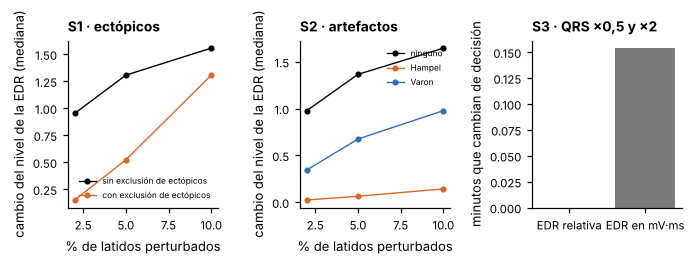

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.4))
for ax, prueba, ops, titulo in ((axs[0], "S1", ["sin exclusión de ectópicos", "con exclusión de ectópicos"], "S1 · ectópicos"),
                                (axs[1], "S2", ["ninguno", "Hampel", "Varon"], "S2 · artefactos")):
    m_ = EST[EST.prueba == prueba].groupby(["nivel", "opción"]).cambio.median().unstack()
    for o, c in zip(ops, ["black", APNEA, NORMAL]):
        ax.plot(100 * m_.index, m_[o], marker="o", ms=3, color=c, label=o)
    ax.set(xlabel="% de latidos perturbados", ylabel="cambio del nivel de la EDR (mediana)", title=titulo)
    ax.legend(fontsize=5.5)
axs[2].bar(["EDR relativa", "EDR en mV·ms"], [FR["relativa"].median(), FR["mV·ms"].median()], color=[NORMAL, GRIS])
axs[2].set(ylabel="minutos que cambian de decisión", title="S3 · QRS ×0,5 y ×2")
fig.tight_layout()
save(fig, "08_estres")

**Qué se ve.** **Las cinco etapas protegen**, en las 19 personas (S5, en las 12 donde la perturbación dejó minutos para comparar), con p de Holm < 0,001:
- **S1, ectópicos (5 % de los latidos):** el nivel de la EDR se mueve 1,31 sin excluirlos y 0,52 excluyéndolos.
- **S2, artefactos (5 %):** 1,36 sin excluir atípicos, 0,67 con el procedimiento de Varon y **0,06 con Hampel**. Hampel protege unas diez veces más que Varon contra este tipo de artefacto.
- **S3, tamaño del QRS:** con la EDR en mV·ms, al multiplicar el ECG por 0,5 o por 2 cambia la decisión en el 15 % de los minutos (mediana; hasta 38 % en una noche). Con la EDR relativa, en ninguno.
- **S4, deriva:** P_RR se mueve 0,008 quitando la media y 0,003 quitando la recta.
- **S5, ritmo irregular:** sin la exclusión cambia la decisión en el 10 % de los minutos perturbados; con la exclusión esos minutos quedan sin decisión.

## 5. ¿Alguna etapa protectora empeora el detector?

Se arma el **candidato**: todas las etapas protectoras, con los atípicos según S2, más el refinamiento del pico R, spline cúbico, sin Wiener y sin medida de confianza. Después se saca una etapa protectora por vez y se mide si el detector **empeora con la etapa**:
- la exactitud en validación cruzada, con el bootstrap que repite el ajuste (2000 sorteos);
- para las etapas de la EDR, además P2 (4000 sorteos).

La diferencia se escribe candidato − sin la etapa: **un valor negativo quiere decir que la etapa empeora**.

In [17]:
s2_h = TAB_S.loc["S2 · artefactos (Hampel)", "protege"] == "sí"
s2_v = TAB_S.loc["S2 · artefactos (Varon)", "protege"] == "sí"
ATIP = "Varon" if s2_v else ("Hampel" if s2_h else "ninguno")
CAND = {**CAND_BASE, "aberrant": ATIP == "Varon", "hampel": ATIP == "Hampel"}
print("atípicos en el candidato:", ATIP)
T_CAND = tablas_det(CAND, "linear")
VARS_NI = {"EDR relativa": ({**CAND, "relative": False}, "linear", MINUTE_MAX),
           "excluir ectópicos": ({**CAND, "exclude_ectopic": False}, "linear", MINUTE_MAX),
           "excluir minutos con > 20 % corregidos": (CAND, "linear", None),
           "quitar la recta": (CAND, "constant", MINUTE_MAX)}
if ATIP != "ninguno":
    VARS_NI[f"excluir atípicos ({ATIP})"] = ({**CAND, "aberrant": False, "hampel": False}, "linear", MINUTE_MAX)
T_NI = {k: (T_CAND if (kw == CAND and dt == "linear") else tablas_det(kw, dt), mc) for k, (kw, dt, mc) in VARS_NI.items()}


def marcar(E_a, E_b):
    clave = lambda e: pd.MultiIndex.from_frame(e[["record", "minute"]])
    comun = clave(E_a).intersection(clave(E_b))
    return E_a.assign(com=clave(E_a).isin(comun)), E_b.assign(com=clave(E_b).isin(comun))


_B = {}


def _trabajo_ni(semillas):
    Ea, Eb = _B["E"]; personas = _B["personas"]
    out = []
    for s in semillas:
        mu = np.random.default_rng([2026, s]).choice(personas, len(personas))
        ra, rb = cv_c(replicar_personas(Ea, mu)), cv_c(replicar_personas(Eb, mu))
        oka, okb = (ra.pred == ra.label).to_numpy() & ra.com.to_numpy(), (rb.pred == rb.label).to_numpy() & rb.com.to_numpy()
        out.append(oka.sum() / ra.com.sum() - okb.sum() / rb.com.sum())
    return out


def boot_ni(Ea, Eb, n=None):
    n = n or (40 if RAPIDO else 2000)
    _B.update(E=(Ea, Eb), personas=np.asarray(PERSONAS))
    with ProcessPoolExecutor(4) as ex:
        return np.array([x for b in ex.map(_trabajo_ni, np.array_split(np.arange(n), 40)) for x in b])


E_CAND = con_ev(T_CAND, MINUTE_MAX).reset_index(drop=True)
r_cand = cv_c(E_CAND)
RES_NI = {}
for nombre, (T_v, mc) in T_NI.items():
    Ea, Eb = marcar(E_CAND, con_ev(T_v, mc).reset_index(drop=True))
    rv = cv_c(Eb)
    oka = ((r_cand.pred == r_cand.label) & Ea.com.reindex(r_cand.index).to_numpy()).sum() / Ea.com.sum()
    m_ = r_cand.merge(rv, on=["record", "minute"], suffixes=("_a", "_b"))
    d = float(((m_.pred_a == m_.label_a).mean()) - ((m_.pred_b == m_.label_b).mean()))
    boot = boot_ni(Ea, Eb)
    RES_NI[f"exactitud · {nombre}"] = (d, boot)
for nombre in ("EDR relativa", "excluir ectópicos") + ((f"excluir atípicos ({ATIP})",) if ATIP != "ninguno" else ()):
    niv_a = T_CAND.groupby("record").EDR_noche.first().reindex(recs).to_numpy()
    niv_b = T_NI[nombre][0].groupby("record").EDR_noche.first().reindex(recs).to_numpy()
    d = spearmanr(niv_a, frac)[0] - spearmanr(niv_b, frac)[0]
    boot = np.array([spearmanr(niv_a[i], frac[i])[0] - spearmanr(niv_b[i], frac[i])[0] for i in idx_sorteos])
    RES_NI[f"P2 · {nombre}"] = (d, boot)
ph_ni = holm({k: p_bootstrap(b) for k, (_, b) in RES_NI.items()})
TAB_NI = pd.DataFrame({"candidato − sin la etapa": {k: v[0] for k, v in RES_NI.items()},
                       "IC 95 %": {k: f"{np.nanpercentile(v[1], 2.5):+.3f} a {np.nanpercentile(v[1], 97.5):+.3f}" for k, v in RES_NI.items()},
                       "p": {k: p_bootstrap(v[1]) for k, v in RES_NI.items()}, "p de Holm": ph_ni})
TAB_NI["la etapa empeora de forma demostrable"] = np.where((TAB_NI["candidato − sin la etapa"] < 0) & (TAB_NI["p de Holm"] < 0.05), "sí", "no")
TAB_NI

atípicos en el candidato: Varon


,candidato − sin la etapa,IC 95 %,p,p de Holm,la etapa empeora de forma demostrable
exactitud · EDR relativa,0.058449,-0.026 a +0.179,0.2050,1.0,no
exactitud · excluir ectópicos,-0.007202,-0.015 a +0.014,0.8390,1.0,no
exactitud · excluir minutos con > 20 % corregidos,-0.005797,-0.012 a +0.016,0.9570,1.0,no
exactitud · quitar la recta,-0.000220,-0.005 a +0.007,0.6190,1.0,no
exactitud · excluir atípicos (Varon),0.000966,-0.006 a +0.008,0.9700,1.0,no
P2 · EDR relativa,0.072523,-0.124 a +0.332,0.4490,1.0,no
P2 · excluir ectópicos,0.002487,-0.012 a +0.017,0.8325,1.0,no
P2 · excluir atípicos (Varon),0.000289,-0.017 a +0.016,0.8990,1.0,no


**Qué se ve.** Ninguna etapa protectora empeora el detector de forma demostrable, ni en exactitud ni en P2 (p de Holm = 1 en todas). Las diferencias son chicas, y casi todas a favor de la etapa o en cero.

## 6. Decisión y chequeo contra la versión evaluada en test

In [18]:
def empeora(nombre):
    filas_ = [k for k in TAB_NI.index if k.endswith(nombre)]
    return any(TAB_NI.loc[k, "la etapa empeora de forma demostrable"] == "sí" for k in filas_)


DEC = {"EDR relativa": ("S3 · tamaño del QRS (EDR relativa)", "EDR relativa"),
       "excluir ectópicos": ("S1 · ectópicos (excluirlos)", "excluir ectópicos"),
       "quitar la recta": ("S4 · deriva (quitar la recta)", "quitar la recta"),
       "excluir minutos con > 20 % corregidos": ("S5 · ritmo irregular (excluir minutos)", "excluir minutos con > 20 % corregidos")}
if ATIP != "ninguno":
    DEC[f"excluir atípicos ({ATIP})"] = (f"S2 · artefactos ({ATIP})", f"excluir atípicos ({ATIP})")
filas_d = []
for etapa, (s_, ni) in DEC.items():
    protege = TAB_S.loc[s_, "protege"] == "sí"
    peor = empeora(ni)
    filas_d.append({"etapa": etapa, "protege (prueba de estrés)": "sí" if protege else "no",
                    "empeora de forma demostrable": "sí" if peor else "no",
                    "decisión": "se mantiene" if (protege and not peor) else "sale (regla de sencillez de 07)"})
if ATIP == "ninguno":
    filas_d.append({"etapa": "excluir atípicos", "protege (prueba de estrés)": "no", "empeora de forma demostrable": "—", "decisión": "sale"})
DECISION_R = pd.DataFrame(filas_d).set_index("etapa")
DECISION_R

,protege (prueba de estrés),empeora de forma demostrable,decisión
etapa,,,
EDR relativa,sí,no,se mantiene
excluir ectópicos,sí,no,se mantiene
quitar la recta,sí,no,se mantiene
excluir minutos con > 20 % corregidos,sí,no,se mantiene
excluir atípicos (Varon),sí,no,se mantiene


In [19]:
FINAL_R = dict(CAND); DT_R = "linear"; MC_R = MINUTE_MAX
for etapa, fila in DECISION_R.iterrows():
    if fila["decisión"].startswith("sale"):
        if etapa == "EDR relativa": FINAL_R["relative"] = False
        if etapa == "excluir ectópicos": FINAL_R["exclude_ectopic"] = False
        if etapa.startswith("excluir atípicos"): FINAL_R["aberrant"] = FINAL_R["hampel"] = False
        if etapa == "quitar la recta": DT_R = "constant"
        if etapa.startswith("excluir minutos"): MC_R = None
print("detector final:", FINAL_R, "· tendencia:", DT_R, "· máx. RR corregidos por minuto:", MC_R)
T_FR = T_CAND if (FINAL_R == CAND and DT_R == "linear") else tablas_det(FINAL_R, DT_R)
r_fr = cv_c(con_ev(T_FR, MC_R))
E_ACT = con_ev(T_ACT, MINUTE_MAX).reset_index(drop=True)
Ea, Eb = marcar(E_ACT, con_ev(T_FR, MC_R).reset_index(drop=True))
boot_chk = boot_ni(Ea, Eb)
m_ = r_act.merge(r_fr, on=["record", "minute"], suffixes=("_a", "_b"))
d_chk = float((m_.pred_a == m_.label_a).mean() - (m_.pred_b == m_.label_b).mean())
print(f"evaluado en test − final, exactitud sobre {len(m_)} minutos comunes: {d_chk:+.4f} "
      f"(IC 95 % repitiendo el ajuste {np.nanpercentile(boot_chk, 2.5):+.4f} a {np.nanpercentile(boot_chk, 97.5):+.4f}), p = {p_bootstrap(boot_chk):.3f}")
pd.DataFrame([resumen(T_ACT, r_act, "evaluado en test (04)"), resumen(T_SIM, r_sim, "simplificado (07)"),
              resumen(T_FIN, r_fin, "decisiones de la EDR por P2 (§2, no adoptadas)"),
              resumen(T_FR, r_fr, "con el criterio de robustez (final)")]).set_index("detector").T.round(3)

detector final: {'edr_method': 'area', 'wiener': False, 'exclude_ectopic': True, 'hampel': False, 'aberrant': True, 'relative': True, 'interp': 'cubic'} · tendencia: linear · máx. RR corregidos por minuto: 0.2


evaluado en test − final, exactitud sobre 22772 minutos comunes: +0.0137 (IC 95 % repitiendo el ajuste -0.0482 a +0.0506), p = 0.899


detector,evaluado en test (04),simplificado (07),"decisiones de la EDR por P2 (§2, no adoptadas)",con el criterio de robustez (final)
sensibilidad,0.814,0.802,0.767,0.792
especificidad,0.851,0.834,0.768,0.842
exactitud,0.836,0.821,0.768,0.822
P2 · ρ nivel EDR vs % de apnea,0.828,0.781,0.709,0.769
ρ por noche,0.795,0.760,0.673,0.739
% marcado en controles,7.376,12.098,7.000,13.046


In [20]:
from src.features.detector import save_params

p_fr, u_fr = parametros(T_FR, MC_R)
PARAMS_FR = {"feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
             **{k: p_fr[k] for k in ("mu1", "s1", "mu2", "s2", "w")}, "umbral": u_fr,
             "banda_hz": list(BAND), "banda_efectiva_hz": [round(BANDA_EFECTIVA[0], 4), BANDA_EFECTIVA[1]], "ventana_s": WINDOW_S,
             "etapas": {"refinamiento_pico_r": True, "wiener_edr": FINAL_R["wiener"], "excluir_ectopicos_edr": FINAL_R["exclude_ectopic"],
                        "hampel_edr": FINAL_R["hampel"], "aberrantes_varon_edr": FINAL_R["aberrant"], "edr_relativa": FINAL_R["relative"],
                        "interpolacion": FINAL_R["interp"], "tendencia_welch": DT_R, "max_rr_corregidos_por_minuto": MC_R, "confianza": False},
             "fijado_con": "47 registros de desarrollo (notebooks/08_edr_nivel_noche.ipynb, sección 6)",
             "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente todavía"}
if not RAPIDO:
    save_params(ROOT / "docs" / "parametros_final.json", PARAMS_FR)
print(json.dumps(PARAMS_FR, indent=2, ensure_ascii=False))

{
  "feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
  "mu1": -1.4915729639776574,
  "s1": 0.5902302539907761,
  "mu2": -1.9818740645720423,
  "s2": 0.5990667525147634,
  "w": 1.0,
  "umbral": 0.5445300189914863,
  "banda_hz": [
    0.01,
    0.05
  ],
  "banda_efectiva_hz": [
    0.0167,
    0.05
  ],
  "ventana_s": 240,
  "etapas": {
    "refinamiento_pico_r": true,
    "wiener_edr": false,
    "excluir_ectopicos_edr": true,
    "hampel_edr": false,
    "aberrantes_varon_edr": true,
    "edr_relativa": true,
    "interpolacion": "cubic",
    "tendencia_welch": "linear",
    "max_rr_corregidos_por_minuto": 0.2,
    "confianza": false
  },
  "fijado_con": "47 registros de desarrollo (notebooks/08_edr_nivel_noche.ipynb, sección 6)",
  "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente todavía"
}


**Qué se ve.**
- **Se mantienen todas las etapas protectoras**: EDR relativa, exclusión de ectópicos, exclusión de atípicos, exclusión de minutos con más de 20 % de RR corregidos y quitar la recta. Salen el Wiener y la medida de confianza, y la interpolación pasa a spline cúbico.
- **Para los atípicos, la regla registrada eligió el procedimiento de Varon** (el publicado), porque los dos protegen y ninguno empeora. Pero S2 muestra que **Hampel protege unas diez veces más**. Además, el detector final marca más minutos en los controles que la versión evaluada en test (13,0 % contra 7,4 %), probablemente por las dos noches de control de una misma persona (c10 y x18) cuyos artefactos atrapa Hampel. Esta parte se informa como pendiente de decisión.
- **El detector final no es peor que la versión evaluada en test de forma demostrable:** exactitud 0,822 contra 0,836 (diferencia +0,014, IC −0,048 a +0,051 repitiendo el ajuste, p = 0,90).
- **Sus parámetros están en `docs/parametros_final.json`.** No tiene una evaluación independiente hasta que se evalúe en test, una sola vez, con un notebook registrado antes de ejecutarse.